# Projeto Aplicado — Sprint 2 · RFM e Clusterização (base Olist)
**Segmentação de Clientes por Valor (RFM e Clusterização) para Otimização de Marketing e Retenção em E-commerce de Moda**

Aluno: Fábio Roberto Gomes Filho · Orientador: Marcos Prochnow · Pós-graduação em Ciência de Dados com IA (XP Educação)

| Sprint 2 | 09/11 – 15/11/2026 |
|---|---|
| R06 | Calcular Recência, Frequência e Valor por cliente |
| R07 | Gerar o escore RFM por quintis e a segmentação por regras (linha de base) |
| R08 | Pré-processar os dados para clusterização |
| R09 | Definir o número de grupos e treinar o K-Means |
| R10 | Validar os clusters |
| R11 | Interpretar e nomear os segmentos |

> Entrada: `PROCESSADOS/olist_pedidos_tratados.parquet` (Sprint 1, R03). A aplicação na base da LLVE é feita na Sprint 3 (R12), com o mesmo pipeline.

## Preparação do ambiente

In [2]:
from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path
import random, numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns

BASE_DIR   = Path('/content/drive/MyDrive/PROJETO APLICADO CD/PROJETO APLICADO')
OUTPUT_DIR = BASE_DIR / 'PROCESSADOS'
FIG_DIR    = BASE_DIR / 'FIGURAS'
SEED = 42
random.seed(SEED); np.random.seed(SEED)

pd.set_option('display.max_columns', 50)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')
sns.set_theme(style='whitegrid', context='notebook')
COR, COR_DESTAQUE, COR_NEUTRA = '#2E7D5B', '#C0392B', '#9AA5B1'

def salvar(nome):
    plt.savefig(FIG_DIR / f'{nome}.png', dpi=200, bbox_inches='tight')

pedidos = pd.read_parquet(OUTPUT_DIR / 'olist_pedidos_tratados.parquet')
print(f'{len(pedidos):,} pedidos · {pedidos["customer_unique_id"].nunique():,} clientes')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
96,379 pedidos · 93,261 clientes


---
## R06 · Cálculo de Recência, Frequência e Valor por cliente
**Critério de aceite:** tabela RFM por cliente.

Decisões (registradas para o relatório):
| # | Decisão | Justificativa |
|---|---|---|
| S1 | **Data de referência** = dia seguinte ao último pedido da base (Olist: 30/08/2018) | Padrão da literatura; não depende da data de extração do arquivo. Na LLVE, mesma regra |
| S2 | **Recência (R)** = dias entre a última compra e a data de referência | Quanto menor, mais recente o cliente |
| S3 | **Frequência (F)** = nº de pedidos distintos do cliente; versão ordinal `F_ord` = 1, 2 ou 3+ | 97% dos clientes têm 1 pedido (achado A3); a cauda de 4 a 15 pedidos é agrupada em 3+ |
| S4 | **Valor (M)** = soma do valor pago pelo cliente (D1 da Sprint 1) | Definição clássica do RFM: receita total gerada pelo cliente |

In [3]:
DATA_REF = pedidos['order_purchase_timestamp'].max().normalize() + pd.Timedelta(days=1)

rfm = (pedidos.groupby('customer_unique_id')
       .agg(ultima_compra=('order_purchase_timestamp', 'max'),
            primeira_compra=('order_purchase_timestamp', 'min'),
            F=('order_id', 'nunique'),
            M=('valor_pago', 'sum'),
            uf=('customer_state', 'last')))
rfm['R'] = (DATA_REF - rfm['ultima_compra']).dt.days
rfm['F_ord'] = rfm['F'].clip(upper=3)
rfm['ticket_medio'] = rfm['M'] / rfm['F']
rfm = rfm[['R', 'F', 'F_ord', 'M', 'ticket_medio', 'primeira_compra', 'ultima_compra', 'uf']]

assert rfm.index.is_unique and len(rfm) == pedidos['customer_unique_id'].nunique()
assert np.isclose(rfm['M'].sum(), pedidos['valor_pago'].sum()), 'receita não confere'

print(f'Data de referência: {DATA_REF:%d/%m/%Y} · {len(rfm):,} clientes')
rfm[['R', 'F', 'M']].describe(percentiles=[.2, .4, .5, .6, .8]).T

Data de referência: 30/08/2018 · 93,261 clientes


,count,mean,std,min,20%,40%,50%,60%,80%,max
R,"93,261.00",237.46,152.56,0.00,92.00,177.00,218.00,268.00,382.00,695.00
F,"93,261.00",1.03,0.21,1.00,1.00,1.00,1.00,1.00,1.00,15.00
M,"93,261.00",161.86,195.10,9.59,55.24,87.32,107.78,132.49,208.07,"4,655.91"


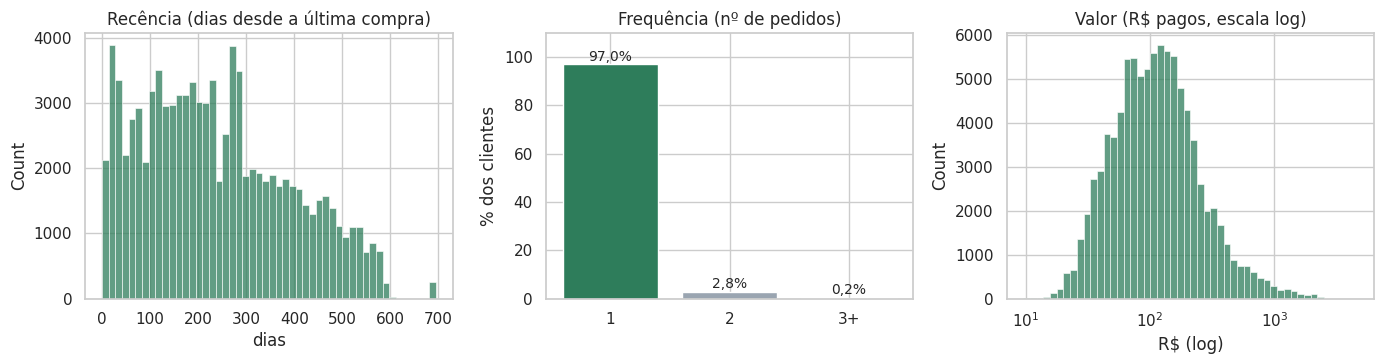

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
sns.histplot(rfm['R'], bins=50, color=COR, ax=axes[0])
axes[0].set_title('Recência (dias desde a última compra)'); axes[0].set_xlabel('dias')

freq = rfm['F_ord'].map({1: '1', 2: '2', 3: '3+'}).value_counts(normalize=True).reindex(['1', '2', '3+']) * 100
axes[1].bar(freq.index, freq.values, color=[COR, COR_NEUTRA, COR_NEUTRA])
for i, v in enumerate(freq.values):
    axes[1].text(i, v + 1.5, f'{v:.1f}%'.replace('.', ','), ha='center', fontsize=10)
axes[1].set_ylim(0, 110); axes[1].set_title('Frequência (nº de pedidos)'); axes[1].set_ylabel('% dos clientes')

sns.histplot(rfm['M'], bins=50, log_scale=True, color=COR, ax=axes[2])
axes[2].set_title('Valor (R$ pagos, escala log)'); axes[2].set_xlabel('R$ (log)')
plt.tight_layout(); salvar('R06_distribuicao_rfm'); plt.show()

In [5]:
arq_rfm = OUTPUT_DIR / 'olist_rfm.parquet'
rfm.to_parquet(arq_rfm)
print(f'Salvo: {arq_rfm.name} · {len(rfm):,} clientes × {rfm.shape[1]} colunas')
rfm.head()

Salvo: olist_rfm.parquet · 93,261 clientes × 8 colunas


,R,F,F_ord,M,ticket_medio,primeira_compra,ultima_compra,uf
customer_unique_id,,,,,,,,
0000366f3b9a7992bf8c76cfdf3221e2,111,1,1,141.90,141.90,2018-05-10 10:56:27,2018-05-10 10:56:27,SP
0000b849f77a49e4a4ce2b2a4ca5be3f,114,1,1,27.19,27.19,2018-05-07 11:11:27,2018-05-07 11:11:27,SP
0000f46a3911fa3c0805444483337064,537,1,1,86.22,86.22,2017-03-10 21:05:03,2017-03-10 21:05:03,SC
0000f6ccb0745a6a4b88665a16c9f078,321,1,1,43.62,43.62,2017-10-12 20:29:41,2017-10-12 20:29:41,PA
0004aac84e0df4da2b147fca70cf8255,288,1,1,196.89,196.89,2017-11-14 19:45:42,2017-11-14 19:45:42,SP


### Checklist do R06
- [x] Data de referência definida (S1) e Recência calculada em dias (S2)
- [x] Frequência por pedidos distintos e versão ordinal 1 / 2 / 3+ (S3)
- [x] Valor = soma do valor pago, com conferência da receita total (S4)
- [x] Figura `FIGURAS/R06_distribuicao_rfm.png` exportada
- [x] Tabela RFM salva em `PROCESSADOS/olist_rfm.parquet`

---
## R07 · Escore RFM por quintis e segmentação por regras (linha de base)
**Critério de aceite:** segmentos de referência.

Decisões:
| # | Decisão | Justificativa |
|---|---|---|
| S5 | Notas de **R** e **M** por quintis (1 a 5); em R, nota 5 = compra mais recente | Escore clássico do RFM. Empates resolvidos pela ordem (`rank(method='first')`) para gerar quintis de tamanho igual |
| S6 | Nota de **F** por faixas fixas: 1 pedido = 1; 2 pedidos = 3; 3+ pedidos = 5 | Quintis são impossíveis em F (os quatro cortes caem em 1 pedido) |
| S7 | **5 segmentos do projeto**, por regras aplicadas em ordem de prioridade (quadro abaixo) | Mesmos nomes do relatório e do playbook; servem de comparação para o K-Means (R10) |

| Ordem | Segmento | Regra |
|---|---|---|
| 1 | Campeões | Recomprou (F ≥ 3) **e** R ≥ 3 **e** M ≥ 4 |
| 2 | Recorrentes | Recomprou (F ≥ 3) **e** R ≥ 3 |
| 3 | Em Risco | Recomprou com R ≤ 2, **ou** compra única de alto valor (M ≥ 4) com R ≤ 3 |
| 4 | Compra Única Recente | Compra única **e** R ≥ 4 |
| 5 | Inativos | Demais clientes (compra única, antiga e de valor baixo ou médio) |

In [6]:
rfm['R_score'] = pd.qcut(rfm['R'].rank(method='first'), 5, labels=[5, 4, 3, 2, 1]).astype(int)
rfm['M_score'] = pd.qcut(rfm['M'].rank(method='first'), 5, labels=[1, 2, 3, 4, 5]).astype(int)
rfm['F_score'] = np.select([rfm['F'] >= 3, rfm['F'] == 2], [5, 3], default=1)
rfm['RFM_score'] = rfm['R_score'].astype(str) + rfm['F_score'].astype(str) + rfm['M_score'].astype(str)

limites = pd.DataFrame({
    'R (dias)': rfm.groupby('R_score')['R'].agg(['min', 'max']).astype(int).astype(str).agg(' – '.join, axis=1),
    'M (R$)': rfm.groupby('M_score')['M'].agg(['min', 'max']).round(2).astype(str).agg(' – '.join, axis=1),
})
limites.index.name = 'nota'
limites

,R (dias),M (R$)
nota,,
1,382 – 695,9.59 – 55.24
2,268 – 382,55.24 – 87.32
3,177 – 268,87.32 – 132.49
4,92 – 177,132.49 – 208.07
5,0 – 92,208.07 – 4655.91


In [7]:
recomprou = rfm['F_score'] >= 3
condicoes = [
    recomprou & (rfm['R_score'] >= 3) & (rfm['M_score'] >= 4),
    recomprou & (rfm['R_score'] >= 3),
    (recomprou & (rfm['R_score'] <= 2)) | (~recomprou & (rfm['M_score'] >= 4) & (rfm['R_score'] <= 3)),
    ~recomprou & (rfm['R_score'] >= 4),
]
SEGMENTOS = ['Campeões', 'Recorrentes', 'Em Risco', 'Compra Única Recente', 'Inativos']
rfm['segmento_regra'] = np.select(condicoes, SEGMENTOS[:4], default='Inativos')

perfil_regra = (rfm.groupby('segmento_regra')
    .agg(clientes=('R', 'size'), R_mediana=('R', 'median'), F_media=('F', 'mean'),
         M_mediana=('M', 'median'), receita=('M', 'sum'))
    .reindex(SEGMENTOS))
perfil_regra['% clientes'] = perfil_regra['clientes'] / perfil_regra['clientes'].sum() * 100
perfil_regra['% receita'] = perfil_regra['receita'] / perfil_regra['receita'].sum() * 100
perfil_regra

,clientes,R_mediana,F_media,M_mediana,receita,% clientes,% receita
segmento_regra,,,,,,,
Campeões,1481,129.00,2.16,269.12,"538,064.75",1.59,3.56
Recorrentes,324,135.50,2.02,100.74,"31,839.96",0.35,0.21
Em Risco,21666,314.00,1.05,206.87,"6,292,149.78",23.23,41.68
Compra Única Recente,36100,92.00,1.00,108.05,"5,793,254.88",38.71,38.38
Inativos,33690,314.00,1.00,69.61,"2,440,064.35",36.12,16.16


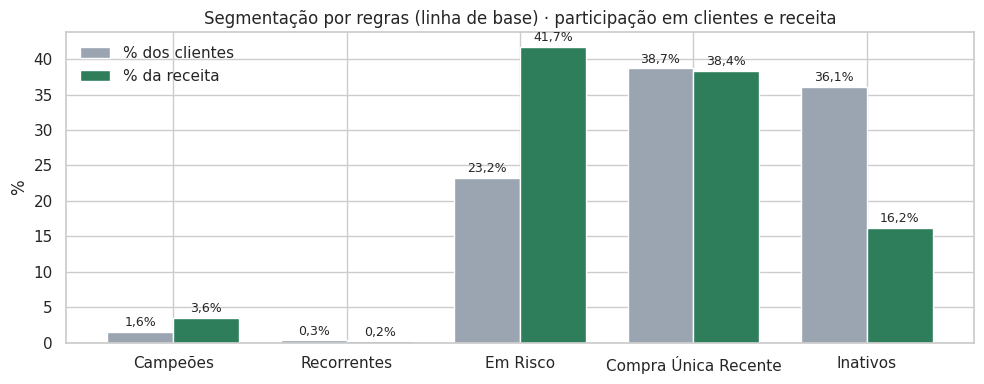

In [8]:
fig, ax = plt.subplots(figsize=(10, 4))
x = np.arange(len(SEGMENTOS)); w = 0.38
ax.bar(x - w/2, perfil_regra['% clientes'], w, color=COR_NEUTRA, label='% dos clientes')
ax.bar(x + w/2, perfil_regra['% receita'], w, color=COR, label='% da receita')
for i, (a, b) in enumerate(zip(perfil_regra['% clientes'], perfil_regra['% receita'])):
    ax.text(i - w/2, a + 0.8, f'{a:.1f}%'.replace('.', ','), ha='center', fontsize=9)
    ax.text(i + w/2, b + 0.8, f'{b:.1f}%'.replace('.', ','), ha='center', fontsize=9)
ax.set_xticks(x); ax.set_xticklabels(SEGMENTOS); ax.set_ylabel('%')
ax.set_title('Segmentação por regras (linha de base) · participação em clientes e receita')
ax.legend(frameon=False)
plt.tight_layout(); salvar('R07_segmentos_regra'); plt.show()

In [9]:
rfm.to_parquet(arq_rfm)
print(f'Atualizado: {arq_rfm.name} · colunas: {list(rfm.columns)}')

Atualizado: olist_rfm.parquet · colunas: ['R', 'F', 'F_ord', 'M', 'ticket_medio', 'primeira_compra', 'ultima_compra', 'uf', 'R_score', 'M_score', 'F_score', 'RFM_score', 'segmento_regra']


### Checklist do R07
- [x] Notas de R e M por quintis e de F por faixas fixas (S5, S6)
- [x] Código RFM de 3 dígitos por cliente
- [x] 5 segmentos de referência por regras (S7), com perfil e participação na receita
- [x] Figura `FIGURAS/R07_segmentos_regra.png` exportada
- [x] Tabela RFM atualizada em `PROCESSADOS/olist_rfm.parquet`